<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/PetrolConsumptionPredictionUsingAnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Mean Absolute Error: 493.85235595703125
Mean Squared Error: 251187.78125
R2 Score: -36.441036224365234


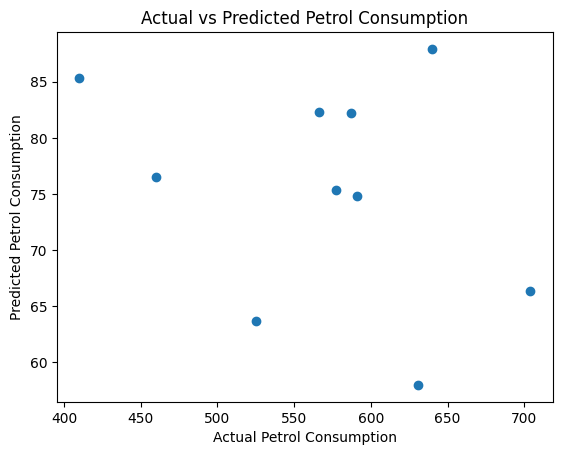

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers

df = pd.read_csv("Petrol Consumption.csv")

X = df.drop("Petrol_Consumption", axis=1)
y = df["Petrol_Consumption"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    layers.Dense(64, activation="relu", input_shape=(4,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.fit(X_train, y_train, epochs=100, verbose=0)

predictions = model.predict(X_test).flatten()

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("Mean Squared Error:", mean_squared_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

plt.scatter(y_test, predictions)
plt.xlabel("Actual Petrol Consumption")
plt.ylabel("Predicted Petrol Consumption")
plt.title("Actual vs Predicted Petrol Consumption")
plt.show()